# Task 4: Social media sentiment around an event

## Introduction
We look at GameStop (GME) in January 2021.
Many retail investors talked about it online.
As attention we use daily Wikipedia views of the GameStop page.
Views on day t are known after the day ends.
So for prediction we use views on day t and the return on day t+1.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
import requests

In [2]:
start = "2020-10-01"
end = "2021-05-01"
ticker = "GME"

prices = yf.download(ticker, start=start, end=end, auto_adjust=True, progress=False)
prices = prices["Close"][ticker].to_frame("Close")

prices.tail()

,Close
Date,
2021-04-26,42.232498
2021-04-27,44.442501
2021-04-28,44.645000
2021-04-29,44.047501
2021-04-30,43.397499


In [3]:
url = (
    "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article/"
    "en.wikipedia/all-access/user/GameStop/daily/20201001/20210430"
)

response = requests.get(url, headers={"User-Agent": "student-homework"})
items = response.json()["items"]

views = pd.DataFrame(items)
views["Date"] = pd.to_datetime(views["timestamp"].str[:8])
views = views.set_index("Date")[["views"]]

views.tail()

,views
Date,
2021-04-26,1909
2021-04-27,2234
2021-04-28,1777
2021-04-29,1556
2021-04-30,1288


In [4]:
df = prices.join(views, how="inner")

df["Return"] = df["Close"].pct_change()
df["Volatility"] = df["Return"].rolling(5).std() * np.sqrt(252)

df["Log_Views"] = np.log(df["views"])
trailing_mean = df["Log_Views"].rolling(20).mean().shift(1)
trailing_std = df["Log_Views"].rolling(20).std().shift(1)
df["Attention_Z"] = (df["Log_Views"] - trailing_mean) / trailing_std

df = df.dropna()
df.head()

,Close,views,Return,Volatility,Log_Views,Attention_Z
Date,,,,,,
2020-10-29,2.9325,859,-0.007614,0.713805,6.755769,-0.249609
2020-10-30,2.6175,787,-0.107417,0.643782,6.668228,-0.662942
2020-11-02,2.6875,896,0.026743,0.836273,6.797940,-0.272407
2020-11-03,2.8925,1076,0.076279,1.164696,6.981006,0.492510
2020-11-04,2.7275,1010,-0.057044,1.134511,6.917706,0.057704


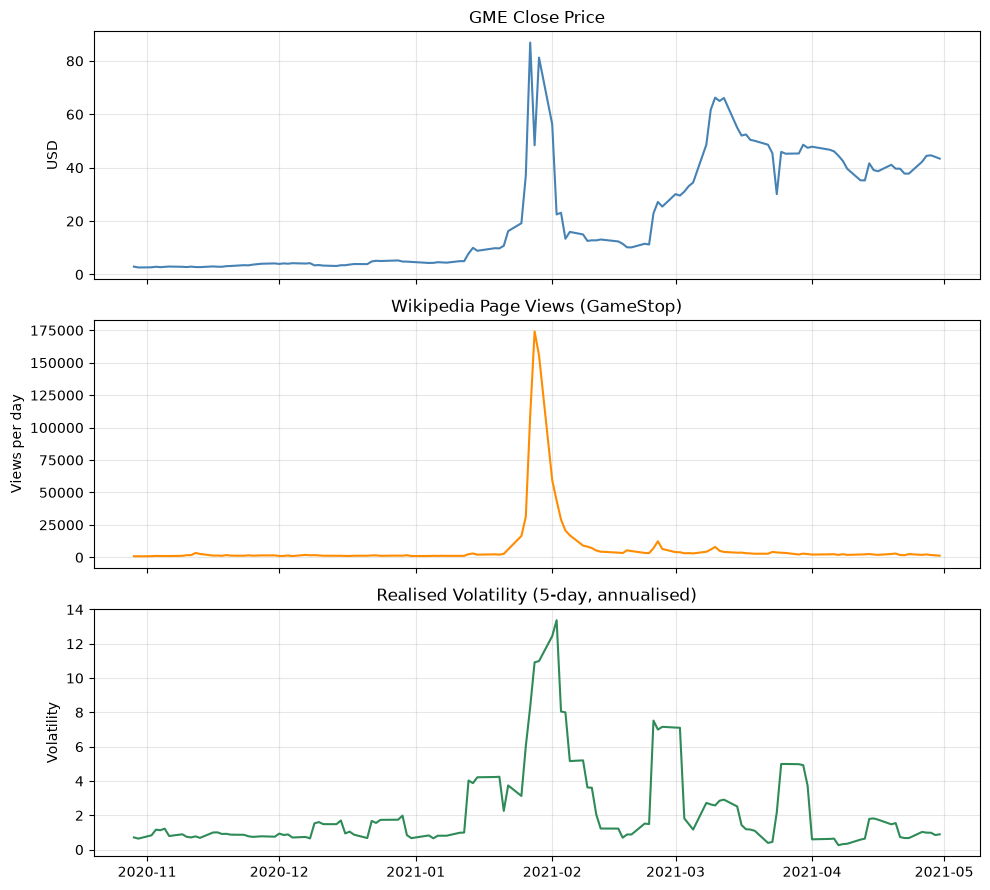

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

axes[0].plot(df.index, df["Close"], color="steelblue")
axes[0].set_title("GME Close Price")
axes[0].set_ylabel("USD")

axes[1].plot(df.index, df["views"], color="darkorange")
axes[1].set_title("Wikipedia Page Views (GameStop)")
axes[1].set_ylabel("Views per day")

axes[2].plot(df.index, df["Volatility"], color="seagreen")
axes[2].set_title("Realised Volatility (5-day, annualised)")
axes[2].set_ylabel("Volatility")

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
core = pd.DataFrame({
    "Pair": [
        "Attention vs same-day return",
        "Attention vs same-day absolute return",
        "Attention vs realised volatility",
    ],
    "Correlation": [
        df["Attention_Z"].corr(df["Return"]),
        df["Attention_Z"].corr(df["Return"].abs()),
        df["Attention_Z"].corr(df["Volatility"]),
    ]
})

display(core.round(3))

,Pair,Correlation
0,Attention vs same-day return,0.328
1,Attention vs same-day absolute return,0.459
2,Attention vs realised volatility,0.328


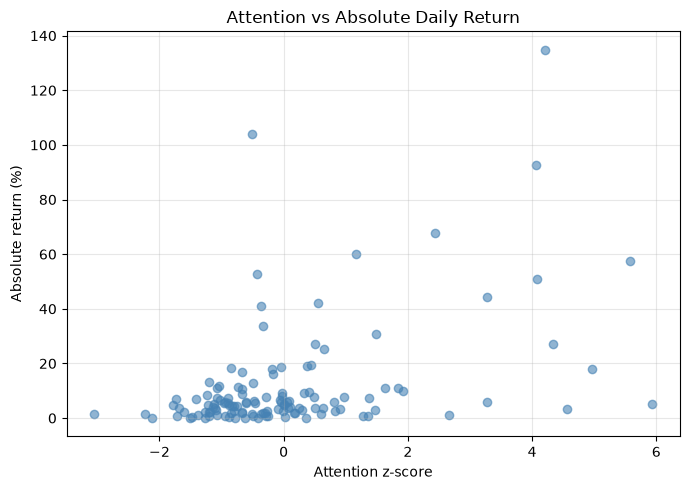

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(df["Attention_Z"], df["Return"].abs() * 100, color="steelblue", alpha=0.6)
plt.title("Attention vs Absolute Daily Return")
plt.xlabel("Attention z-score")
plt.ylabel("Absolute return (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Stretch task

In [8]:
df["Next_Return"] = df["Return"].shift(-1)
stretch = df.dropna()

compare = pd.DataFrame({
    "Relationship": ["Contemporaneous (same day)", "Predictive (next day)"],
    "Correlation": [
        stretch["Attention_Z"].corr(stretch["Return"]),
        stretch["Attention_Z"].corr(stretch["Next_Return"]),
    ]
})

display(compare.round(3))

,Relationship,Correlation
0,Contemporaneous (same day),0.329
1,Predictive (next day),0.200


In [9]:
slope, intercept = np.polyfit(stretch["Attention_Z"], stretch["Next_Return"], 1)

print(f"Next-day return = {intercept:.4f} + {slope:.4f} * Attention_Z")

Next-day return = 0.0410 + 0.0293 * Attention_Z


In [10]:
threshold = stretch["Attention_Z"].quantile(0.90)
extreme = stretch[stretch["Attention_Z"] >= threshold]
normal = stretch[stretch["Attention_Z"] < threshold]

reversal = pd.DataFrame({
    "Group": ["Extreme attention days", "Other days"],
    "Days": [len(extreme), len(normal)],
    "Avg same-day return (%)": [extreme["Return"].mean() * 100, normal["Return"].mean() * 100],
    "Avg next-day return (%)": [extreme["Next_Return"].mean() * 100, normal["Next_Return"].mean() * 100],
})

display(reversal.round(2))

,Group,Days,Avg same-day return (%),Avg next-day return (%)
0,Extreme attention days,13,31.61,24.20
1,Other days,112,1.18,2.03


In [11]:
details = extreme[["views", "Attention_Z", "Return", "Next_Return"]].copy()
details["Return"] = details["Return"] * 100
details["Next_Return"] = details["Next_Return"] * 100

display(details.round(2))

,views,Attention_Z,Return,Next_Return
Date,,,,
2020-11-10,1661,4.56,-3.39,5.86
2020-11-11,1698,3.28,5.86,-5.28
2020-11-12,3367,5.93,-5.28,-1.08
2020-11-13,2624,2.67,-1.08,9.54
2021-01-13,2431,5.58,57.39,27.10
2021-01-14,2982,4.33,27.10,-11.05
2021-01-21,2674,1.93,9.99,51.08
2021-01-22,6157,4.08,51.08,18.12
2021-01-25,16446,4.96,18.12,92.71


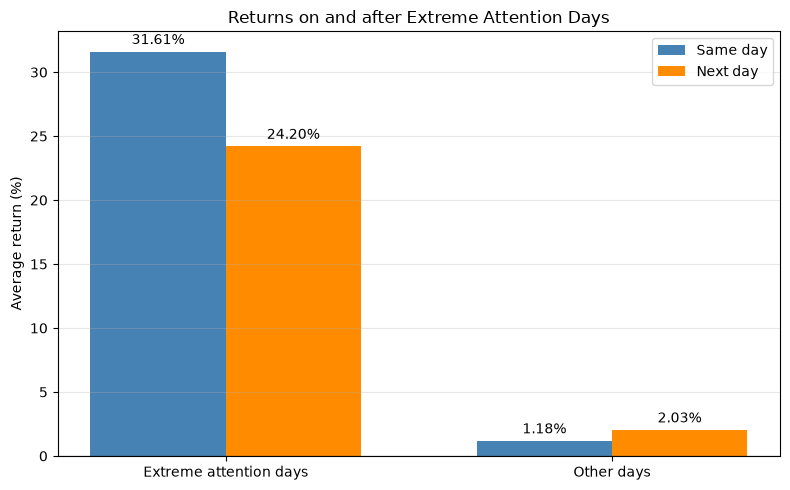

In [12]:
x = np.arange(len(reversal))
width = 0.35

plt.figure(figsize=(8, 5))
bars1 = plt.bar(x - width/2, reversal["Avg same-day return (%)"], width, label="Same day", color="steelblue")
bars2 = plt.bar(x + width/2, reversal["Avg next-day return (%)"], width, label="Next day", color="darkorange")
plt.bar_label(bars1, fmt="%.2f%%", padding=3)
plt.bar_label(bars2, fmt="%.2f%%", padding=3)
plt.xticks(x, reversal["Group"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Returns on and after Extreme Attention Days")
plt.ylabel("Average return (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusions

Views and price went up together.
Views grew from about 1000 to over 170000 per day at the peak.
Attention is linked to big moves and high volatility.
The same day link is stronger than the next day link.
On average there is no reversal after extreme days.
But after the biggest peak days the price fell a lot.
This fits the overreaction idea.

Limits: one stock, small sample, views show attention not tone.
